# Feature exploration — the pre-launch features we plan to use

Companion to `meeting_prep.ipynb`. This notebook looks in detail at every feature the model will use, grouped into eight categories:

| # | Category | Features |
|---|---|---|
| 1 | Pricing | `log_price`, `is_free` |
| 2 | Platform support | `windows`, `mac`, `linux` |
| 3 | Localization | `n_languages`, `has_english`, `n_audio_languages` |
| 4 | Store-page effort | `log_about_len`, `n_screenshots`, `has_website`, `has_support_email` |
| 5 | Content & audience | `required_age`, `has_mature_notes`, `log_achievements` |
| 6 | Business setup | `self_published` |
| 7 | Release timing | `release_month`, `release_weekday` |
| 8 | Game type | genre flags, Steam-category flags |

For most features you get two side-by-side charts — **how common each value is** and **the hit rate for that value** (dashed line = overall hit rate) — followed by the numbers as a table. Section 9 ranks all features against each other.

**Modeling set:** games with SteamSpy data (`Estimated owners` ≠ `"0 - 0"`) released before 2024. **Hit** = at least 100,000 estimated owners.

Run top to bottom (Kernel → Restart & Run All); it takes about a minute.

In [1]:
import csv
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

try:
    display
except NameError:
    display = print

CANDIDATES = [Path("games.csv"), Path("data/games.csv"), Path("../games.csv"), Path("../data/games.csv")]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert CSV_PATH is not None, "Put games.csv next to this notebook (or in data/)."

HIT_THRESHOLD = 100_000
MATURITY_CUTOFF = "2024-01-01"

# ---- Chart style: one consistent palette, light grid, no chart junk ----
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
HIT_COLOR, MISS_COLOR = BLUE, ORANGE
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "figure.dpi": 100, "font.size": 10,
})

In [2]:
# ---- Load (fixes the fused 'DiscountDLC count' header) ----
with open(CSV_PATH, encoding="utf-8", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    first_row = next(reader)
if len(first_row) == len(header) + 1 and "DiscountDLC count" in header:
    i = header.index("DiscountDLC count")
    header[i:i + 1] = ["Discount", "DLC count"]
    df = pd.read_csv(CSV_PATH, names=header, skiprows=1)
else:
    df = pd.read_csv(CSV_PATH)

df["owners_low"] = df["Estimated owners"].astype(str).str.extract(r"^(\d+)").astype(float)[0]
df["release_dt"] = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
df["is_hit"] = (df["owners_low"] >= HIT_THRESHOLD).astype(int)

model_mask = df["Estimated owners"].ne("0 - 0") & (df["release_dt"] < MATURITY_CUTOFF)
g = df[model_mask].copy()
BASE = g["is_hit"].mean()
print(f"Modeling set: {len(g):,} games, {g['is_hit'].sum():,} hits, overall hit rate {BASE:.1%}")

Modeling set: 70,748 games, 7,938 hits, overall hit rate 11.2%


In [3]:
# ---- The 18 base features (same definitions as meeting_prep.ipynb) ----
langs = g["Supported languages"].fillna("[]").str.findall(r"'([^']*)'")
audio = g["Full audio languages"].fillna("[]").str.findall(r"'([^']*)'")

g["log_price"] = np.log1p(g["Price"])
g["is_free"] = (g["Price"] == 0).astype(int)
g["required_age"] = g["Required age"]
g["log_achievements"] = np.log1p(g["Achievements"])
for p in ["Windows", "Mac", "Linux"]:
    g[p.lower()] = g[p].astype(int)
g["n_languages"] = langs.str.len()
g["has_english"] = langs.apply(lambda l: int("English" in l))
g["n_audio_languages"] = audio.str.len()
g["about_len"] = g["About the game"].fillna("").str.len()
g["log_about_len"] = np.log1p(g["about_len"])
g["n_screenshots"] = g["Screenshots"].fillna("").str.count("http")
g["has_website"] = g["Website"].notna().astype(int)
g["has_support_email"] = g["Support email"].notna().astype(int)
g["has_mature_notes"] = g["Notes"].notna().astype(int)
g["self_published"] = (g["Developers"].fillna("") == g["Publishers"].fillna("")).astype(int)
g["release_month"] = g["release_dt"].dt.month
g["release_weekday"] = g["release_dt"].dt.weekday

BASE_FEATURES = ["log_price", "is_free", "windows", "mac", "linux", "n_languages", "has_english",
                 "n_audio_languages", "log_about_len", "n_screenshots", "has_website", "has_support_email",
                 "required_age", "has_mature_notes", "log_achievements", "self_published",
                 "release_month", "release_weekday"]
g[BASE_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_price,70748.0,1.32,0.87,0.0,0.69,1.25,1.94,6.91
is_free,70748.0,0.12,0.32,0.0,0.00,0.00,0.00,1.00
windows,70748.0,1.00,0.02,0.0,1.00,1.00,1.00,1.00
mac,70748.0,0.21,0.41,0.0,0.00,0.00,0.00,1.00
linux,70748.0,0.15,0.36,0.0,0.00,0.00,0.00,1.00
n_languages,70748.0,4.47,10.45,0.0,1.00,1.00,4.00,103.00
has_english,70748.0,0.96,0.19,0.0,1.00,1.00,1.00,1.00
n_audio_languages,70748.0,1.66,8.73,0.0,0.00,0.00,1.00,103.00
log_about_len,70748.0,6.92,0.72,0.0,6.49,6.94,7.37,11.40
n_screenshots,70748.0,9.03,5.66,0.0,5.00,7.00,10.00,183.00


In [4]:
# ---- Chart helpers ----
def rate_table(groups, order=None):
    """Games, share and hit rate for each value of `groups` (a Series aligned with g)."""
    t = g.groupby(groups, observed=True)["is_hit"].agg(games="size", hits="sum", hit_rate="mean")
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    t["share_%"] = t["games"] / len(g) * 100
    t["hit_rate_%"] = t["hit_rate"] * 100
    t.index = t.index.astype(str)
    return t[["games", "share_%", "hits", "hit_rate_%"]].round(1)


def _base_line(ax, horizontal=False):
    if horizontal:
        ax.axvline(BASE * 100, color=INK2, ls="--", lw=1)
    else:
        ax.axhline(BASE * 100, color=INK2, ls="--", lw=1)


def share_and_rate(groups, title, xlabel="", order=None):
    """Two panels: how common each value is, and its hit rate."""
    t = rate_table(groups, order)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
    x = t.index
    a1.bar(x, t["share_%"], color=BLUE, width=0.72, edgecolor=SURFACE, linewidth=1)
    a1.set_title("Share of games (%)")
    a2.bar(x, t["hit_rate_%"], color=BLUE, width=0.72, edgecolor=SURFACE, linewidth=1)
    _base_line(a2)
    a2.set_title(f"Hit rate (%)  ·  dashed = overall {BASE:.1%}")
    for a in (a1, a2):
        a.set_xlabel(xlabel)
        a.grid(axis="x", visible=False)
        if len(x) > 7 or sum(len(s) for s in x) > 40:
            plt.setp(a.get_xticklabels(), rotation=35, ha="right")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.tight_layout()
    plt.show()
    return t


def share_and_rate_h(t, title, height=None):
    """Horizontal version for long label lists (genres, languages, categories). `t` from rate_table."""
    t = t.sort_values("hit_rate_%")
    h = height or max(3.5, 0.28 * len(t) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, h), sharey=True)
    a1.barh(t.index, t["share_%"], color=BLUE, height=0.72, edgecolor=SURFACE, linewidth=1)
    a1.set_title("Share of games (%)")
    a2.barh(t.index, t["hit_rate_%"], color=BLUE, height=0.72, edgecolor=SURFACE, linewidth=1)
    _base_line(a2, horizontal=True)
    a2.set_title(f"Hit rate (%)  ·  dashed = overall {BASE:.1%}")
    for a in (a1, a2):
        a.grid(axis="y", visible=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.tight_layout()
    plt.show()


def flag_chart(cols, labels, title):
    """Yes/no features: hit rate when the flag is on vs off."""
    rows = []
    for c, lab in zip(cols, labels):
        on, off = g.loc[g[c] == 1, "is_hit"], g.loc[g[c] == 0, "is_hit"]
        rows.append({"feature": lab, "% of games with it": on.size / len(g) * 100,
                     "hit rate % — yes": on.mean() * 100, "hit rate % — no": off.mean() * 100})
    t = pd.DataFrame(rows).set_index("feature").round(1)
    x = np.arange(len(t))
    w = 0.36
    fig, ax = plt.subplots(figsize=(max(5, 1.8 * len(t) + 2), 3.6))
    ax.bar(x - w / 2 - 0.01, t["hit rate % — yes"], w, color=HIT_COLOR, label="has it / yes")
    ax.bar(x + w / 2 + 0.01, t["hit rate % — no"], w, color=MISS_COLOR, label="doesn't / no")
    _base_line(ax)
    ax.set_xticks(x, t.index)
    ax.set_ylabel("hit rate (%)")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    ax.set_title(title)
    fig.tight_layout()
    plt.show()
    return t


def hist_by_class(col, title, xlabel, bins=40, clip=None):
    """Distribution of a numeric feature for hits vs non-hits (each normalized to 100%)."""
    s = g[col] if clip is None else g[col].clip(upper=clip)
    edges = np.histogram_bin_edges(s, bins=bins)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for val, color, lab in [(0, MISS_COLOR, "not hit"), (1, HIT_COLOR, "hit")]:
        part = s[g["is_hit"] == val]
        ax.hist(part, bins=edges, weights=np.full(len(part), 100 / len(part)),
                histtype="step", lw=2, color=color, label=f"{lab} (n={len(part):,})")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% of group")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    plt.show()

---
# 1. Pricing — `log_price`, `is_free`

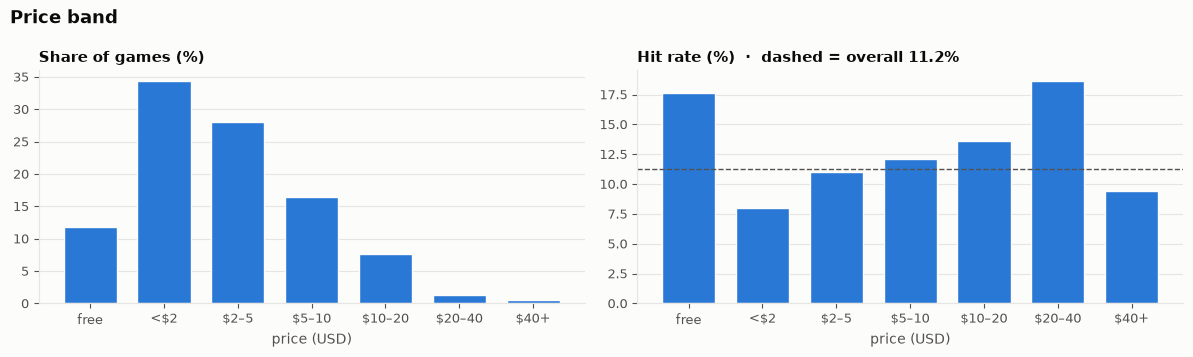

,games,share_%,hits,hit_rate_%
Price,,,,
free,8350,11.8,1472,17.6
<$2,24259,34.3,1942,8.0
$2–5,19809,28.0,2172,11.0
$5–10,11609,16.4,1404,12.1
$10–20,5478,7.7,747,13.6
$20–40,914,1.3,170,18.6
$40+,329,0.5,31,9.4


In [5]:
price_band = pd.cut(g["Price"], [-0.01, 0, 1.99, 4.99, 9.99, 19.99, 39.99, 10_000],
                    labels=["free", "<$2", "$2–5", "$5–10", "$10–20", "$20–40", "$40+"])
share_and_rate(price_band, "Price band", "price (USD)")

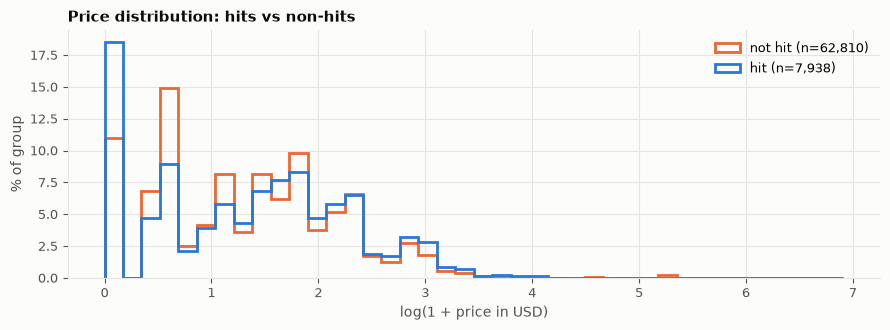

Median price — hits: $2.99   non-hits: $2.49


In [6]:
hist_by_class("log_price", "Price distribution: hits vs non-hits", "log(1 + price in USD)")
print("Median price — hits: ${:.2f}   non-hits: ${:.2f}".format(
    g.loc[g.is_hit == 1, "Price"].median(), g.loc[g.is_hit == 0, "Price"].median()))

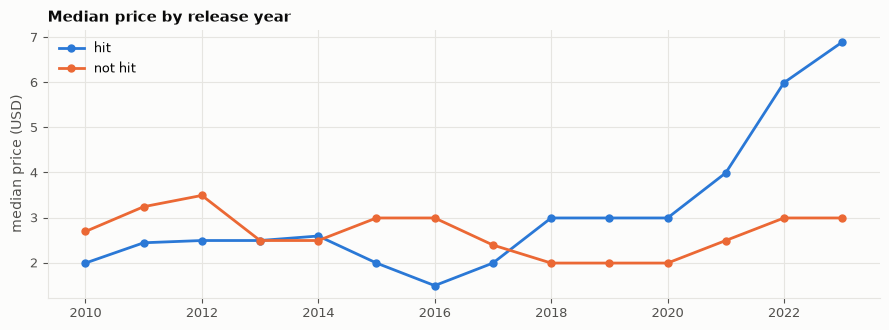

is_hit,median price — not hit,median price — hit
release_dt,,
2010,2.69,1.99
2011,3.24,2.44
2012,3.49,2.49
2013,2.49,2.49
2014,2.49,2.59
2015,2.99,1.99
2016,2.99,1.49
2017,2.39,1.99
2018,1.99,2.99


In [7]:
yr = g[g["release_dt"].dt.year >= 2010]
med = yr.groupby([yr["release_dt"].dt.year, "is_hit"])["Price"].median().unstack()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(med.index, med[1], color=HIT_COLOR, marker="o", ms=5, label="hit")
ax.plot(med.index, med[0], color=MISS_COLOR, marker="o", ms=5, label="not hit")
ax.set_ylabel("median price (USD)")
ax.set_title("Median price by release year")
ax.legend()
fig.tight_layout()
plt.show()
med.round(2).rename(columns={0: "median price — not hit", 1: "median price — hit"})

**Takeaways — pricing**
- The relationship is **not a straight line**: free games hit 17.6 % of the time (free-to-play/MMO), the biggest group — under $2, 34 % of games — hits only 8.0 %, and the rate climbs steadily to 18.6 % at $20–40 before dropping at $40+ (9.4 %, only 329 games, many niche simulators/software).
- That's why `log_price` alone barely separates hits from non-hits (AUC 0.505, §9): the signal is real but U-shaped. Tree models handle that; for logistic regression use price bands.
- **Price interacts with release year:** until ~2017 hits were priced *lower* than non-hits; since 2018 they're priced higher (2023: median $6.89 for hits vs $2.99). The market got flooded with cheap games.

---
# 2. Platform support — `windows`, `mac`, `linux`

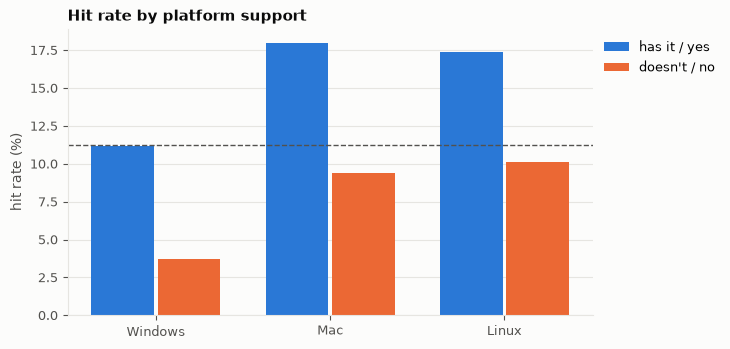

,% of games with it,hit rate % — yes,hit rate % — no
feature,,,
Windows,100.0,11.2,3.7
Mac,21.1,18.0,9.4
Linux,14.8,17.4,10.1


In [8]:
flag_chart(["windows", "mac", "linux"], ["Windows", "Mac", "Linux"], "Hit rate by platform support")

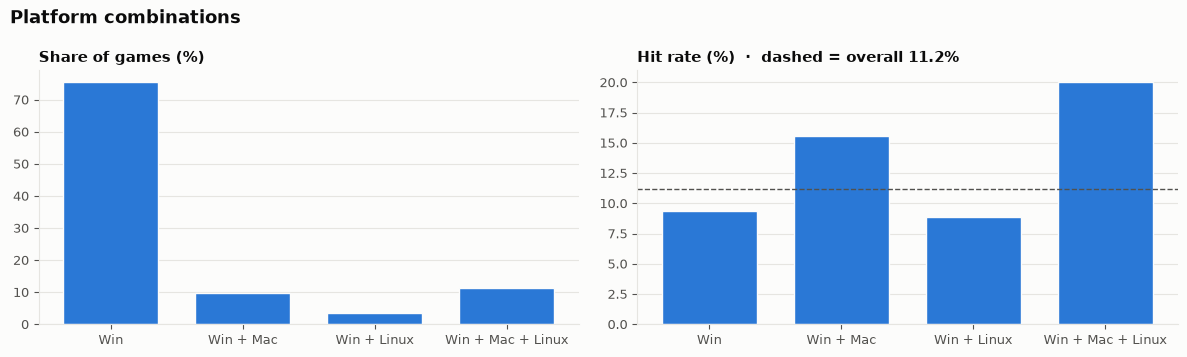

,games,share_%,hits,hit_rate_%
Win,53350,75.4,5036,9.4
Win + Mac,6907,9.8,1078,15.6
Win + Linux,2468,3.5,220,8.9
Win + Mac + Linux,7996,11.3,1603,20.0


In [9]:
def combo(r):
    parts = [n for n, c in [("Win", r.windows), ("Mac", r.mac), ("Linux", r.linux)] if c]
    return " + ".join(parts) if parts else "none listed"
platform_combo = g[["windows", "mac", "linux"]].apply(combo, axis=1)
# Mac-only / Linux-only combinations have fewer than 30 games in total and are left out
share_and_rate(platform_combo, "Platform combinations",
               order=["Win", "Win + Mac", "Win + Linux", "Win + Mac + Linux"])

**Takeaways — platforms**
- **Windows is useless as a feature** — essentially 100 % of games support it. Drop it.
- Mac support nearly doubles the hit rate (18.0 % vs 9.4 %); Linux support also helps (17.4 % vs 10.1 %).
- But the combinations show **Linux helps only together with Mac**: Win + Mac + Linux 20.0 %, Win + Mac 15.6 %, Win + Linux 8.9 % (≈ Windows-only 9.4 %). Mac and Linux are correlated (0.56). Supporting more platforms is likely a proxy for team size/budget.

---
# 3. Localization — `n_languages`, `has_english`, `n_audio_languages`

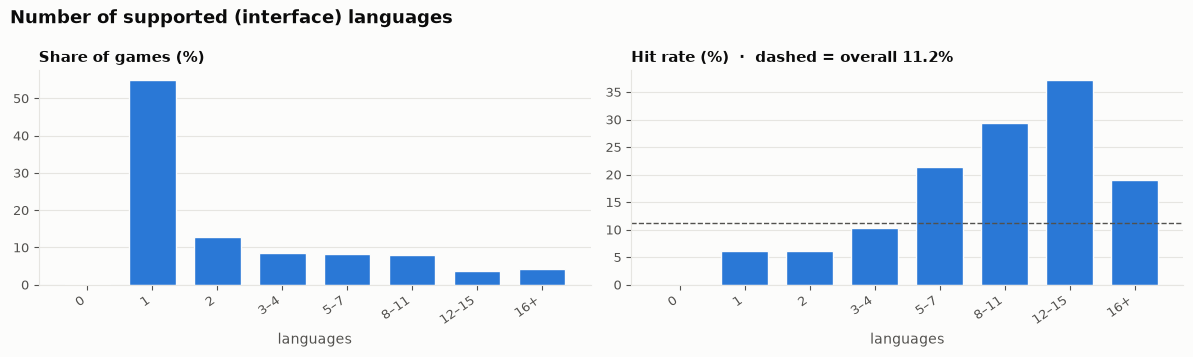

,games,share_%,hits,hit_rate_%
n_languages,,,,
0,47,0.1,0,0.0
1,38735,54.8,2368,6.1
2,9086,12.8,566,6.2
3–4,5938,8.4,609,10.3
5–7,5876,8.3,1253,21.3
8–11,5566,7.9,1630,29.3
12–15,2579,3.6,958,37.1
16+,2921,4.1,554,19.0


In [10]:
lang_bin = pd.cut(g["n_languages"], [-1, 0, 1, 2, 4, 7, 11, 15, 200],
                  labels=["0", "1", "2", "3–4", "5–7", "8–11", "12–15", "16+"])
share_and_rate(lang_bin, "Number of supported (interface) languages", "languages")

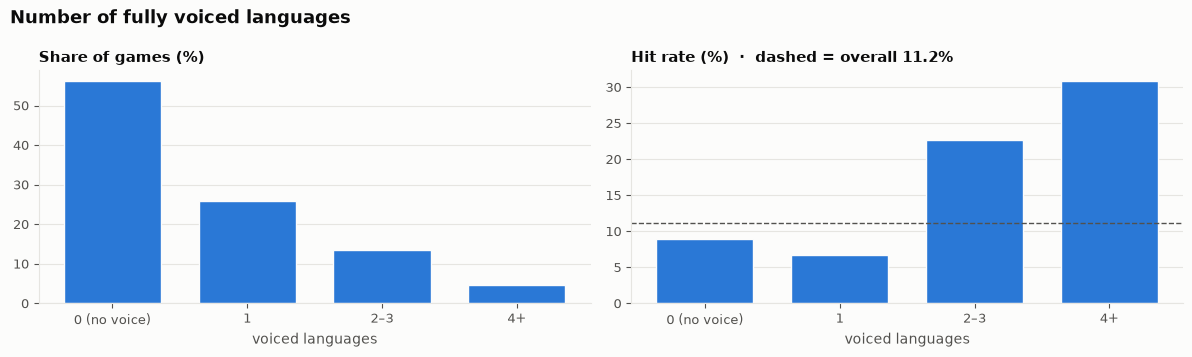

,games,share_%,hits,hit_rate_%
n_audio_languages,,,,
0 (no voice),39658,56.1,3539,8.9
1,18226,25.8,1214,6.7
2–3,9618,13.6,2185,22.7
4+,3246,4.6,1000,30.8


In [11]:
audio_bin = pd.cut(g["n_audio_languages"], [-1, 0, 1, 3, 200], labels=["0 (no voice)", "1", "2–3", "4+"])
share_and_rate(audio_bin, "Number of fully voiced languages", "voiced languages")

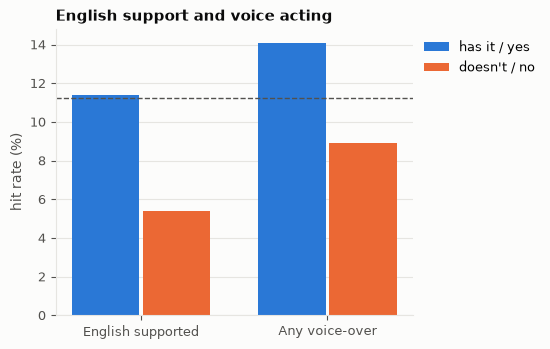

,% of games with it,hit rate % — yes,hit rate % — no
feature,,,
English supported,96.3,11.4,5.4
Any voice-over,43.9,14.1,8.9


In [12]:
g["has_voice"] = (g["n_audio_languages"] > 0).astype(int)
flag_chart(["has_english", "has_voice"], ["English supported", "Any voice-over"], "English support and voice acting")

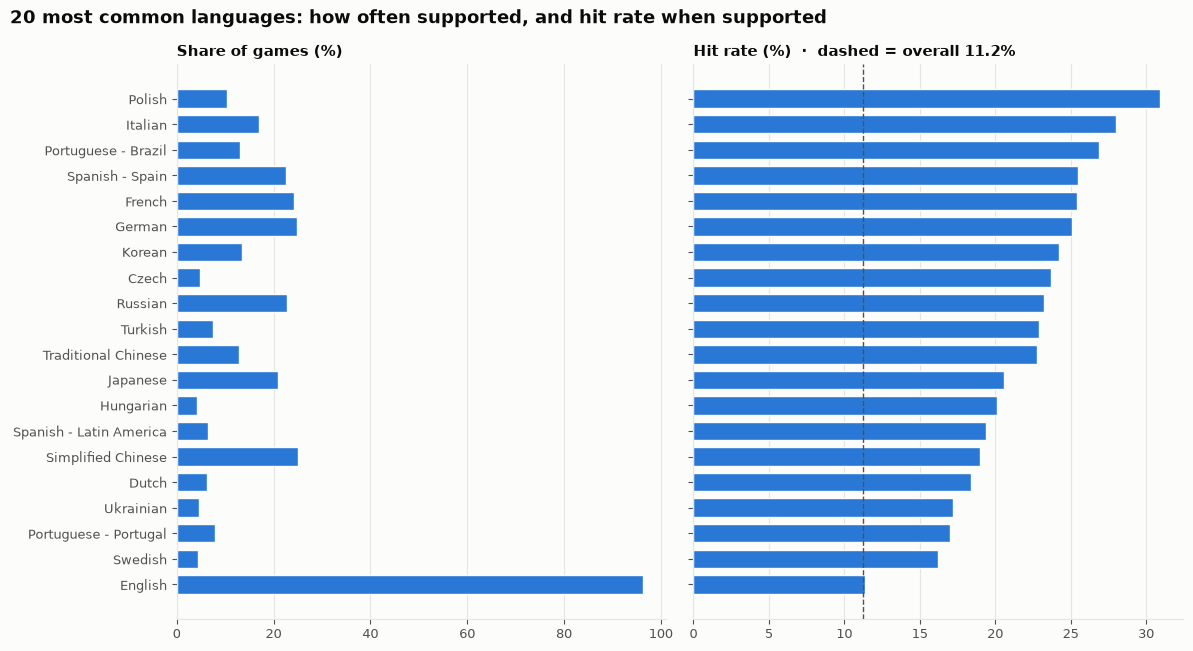

,games,share_%,hits,hit_rate_%
language,,,,
Polish,7278,10.3,2249,30.9
Italian,11977,16.9,3355,28.0
Portuguese - Brazil,9288,13.1,2502,26.9
Spanish - Spain,15935,22.5,4070,25.5
French,17180,24.3,4356,25.4
German,17643,24.9,4436,25.1
Korean,9491,13.4,2300,24.2
Czech,3425,4.8,811,23.7
Russian,16118,22.8,3734,23.2


In [13]:
lang_long = langs.explode().dropna()
lang_long = lang_long[lang_long.str.len().between(2, 40)]
top_langs = lang_long.value_counts().head(20).index
rows = []
for L in top_langs:
    m = langs.apply(lambda l: L in l)
    rows.append({"language": L, "games": int(m.sum()), "share_%": m.mean() * 100,
                 "hits": int(g.loc[m, "is_hit"].sum()), "hit_rate_%": g.loc[m, "is_hit"].mean() * 100})
t_lang = pd.DataFrame(rows).set_index("language").round(1)
share_and_rate_h(t_lang, "20 most common languages: how often supported, and hit rate when supported")
t_lang.sort_values("hit_rate_%", ascending=False)

**Takeaways — localization**
- **The strongest single feature in the dataset** (`n_languages`, AUC 0.69). More than half of games ship in just one language and hit 6.1 % of the time; the rate climbs to 21 % at 5–7 languages, 29 % at 8–11 and 37 % at 12–15.
- It **drops again at 16+ languages (19 %)** — worth investigating (possibly mass machine translation). Trees will capture this; a linear model needs bins.
- Voice acting: 2–3 voiced languages → 22.7 %, 4+ → 30.8 %. Oddly, exactly one voiced language (6.7 %) does slightly worse than none (8.9 %).
- 96 % of games support English; the 4 % that don't hit only 5.4 % of the time.
- Supporting any major European language goes with roughly 25–31 % hit rates (Polish 30.9 %, Italian 28.0 %, Brazilian Portuguese 26.9 %) versus 11.4 % for English. Simplified Chinese is the lowest of the big languages (19.0 %).

---
# 4. Store-page effort — `log_about_len`, `n_screenshots`, `has_website`, `has_support_email`

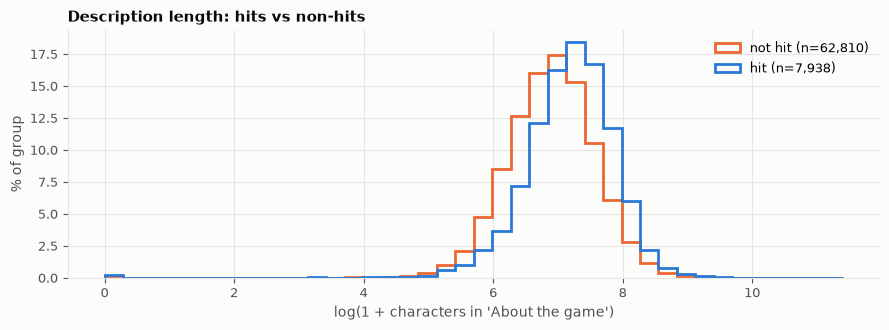

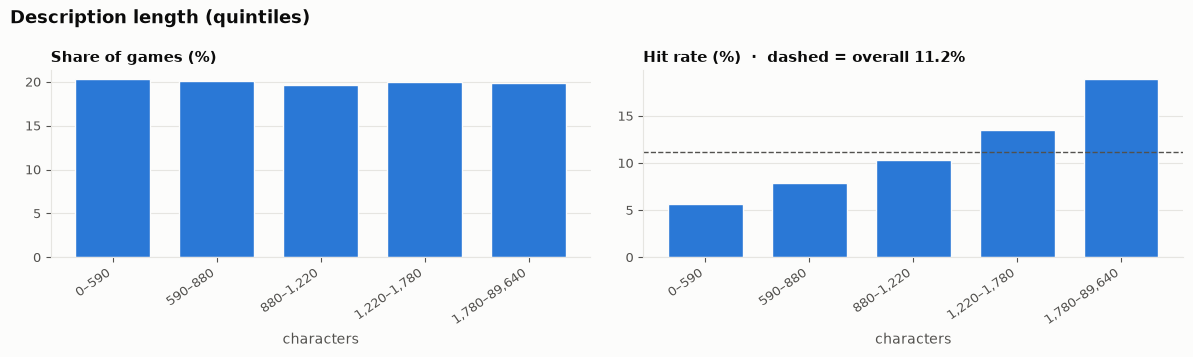

,games,share_%,hits,hit_rate_%
about_len,,,,
0–590,14377,20.3,811,5.6
590–880,14189,20.1,1115,7.9
"880–1,220",13893,19.6,1432,10.3
"1,220–1,780",14181,20.0,1918,13.5
"1,780–89,640",14108,19.9,2662,18.9


In [14]:
hist_by_class("log_about_len", "Description length: hits vs non-hits", "log(1 + characters in 'About the game')")
q = g["about_len"].quantile([0, .2, .4, .6, .8, 1]).round(-1).astype(int).values
about_bin = pd.cut(g["about_len"], q, include_lowest=True, duplicates="drop",
                   labels=[f"{q[i]:,}–{q[i+1]:,}" for i in range(len(q) - 1)])
share_and_rate(about_bin, "Description length (quintiles)", "characters")

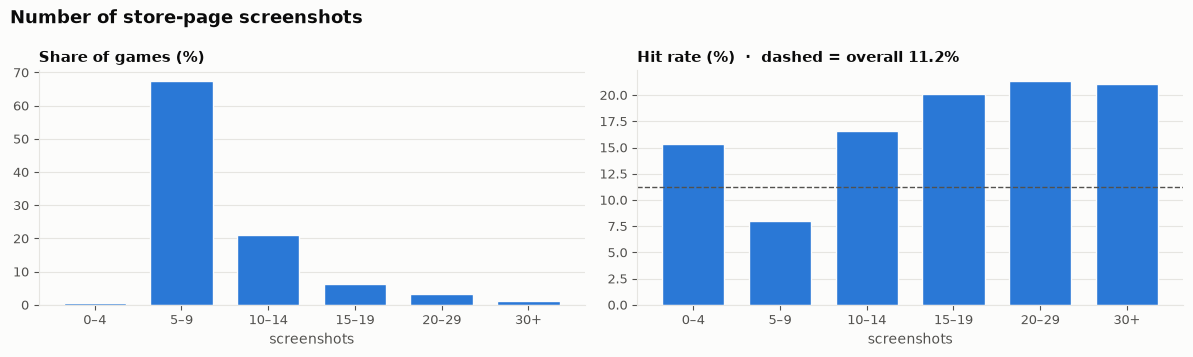

,games,share_%,hits,hit_rate_%
n_screenshots,,,,
0–4,392,0.6,60,15.3
5–9,47643,67.3,3794,8.0
10–14,14965,21.2,2491,16.6
15–19,4554,6.4,915,20.1
20–29,2393,3.4,509,21.3
30+,801,1.1,169,21.1


In [15]:
# Fewer than 5 screenshots is rare (< 1 % of games), so 0–4 is one bin
shot_bin = pd.cut(g["n_screenshots"], [-1, 4, 9, 14, 19, 29, 1000],
                  labels=["0–4", "5–9", "10–14", "15–19", "20–29", "30+"])
share_and_rate(shot_bin, "Number of store-page screenshots", "screenshots")

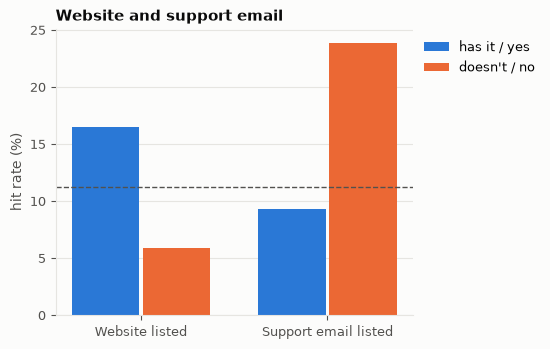

,% of games with it,hit rate % — yes,hit rate % — no
feature,,,
Website listed,50.3,16.5,5.9
Support email listed,87.1,9.3,23.9


In [16]:
flag_chart(["has_website", "has_support_email"], ["Website listed", "Support email listed"],
           "Website and support email")

**Takeaways — store page**
- **Description length** rises steadily with success: shortest fifth 5.6 % → longest fifth 18.9 % (AUC 0.63).
- **Screenshots:** two-thirds of games have 5–9 and hit only 8.0 %; 10–14 → 16.6 %, 15+ → about 20–21 %.
- **Website listed:** 16.5 % vs 5.9 % without — a strong, simple flag (AUC 0.63).
- **Support email is counter-intuitive:** games *without* one hit 23.9 % of the time vs 9.3 % with one. Likely bigger studios use a support site/forum instead of an email address. Keep it; the model can use it, but don't read it causally.
- ⚠️ Gray area: the store page can be edited after launch, so description and screenshot counts reflect today's page, not launch day. Worth raising in the meeting.

---
# 5. Content & audience — `required_age`, `has_mature_notes`, `log_achievements`

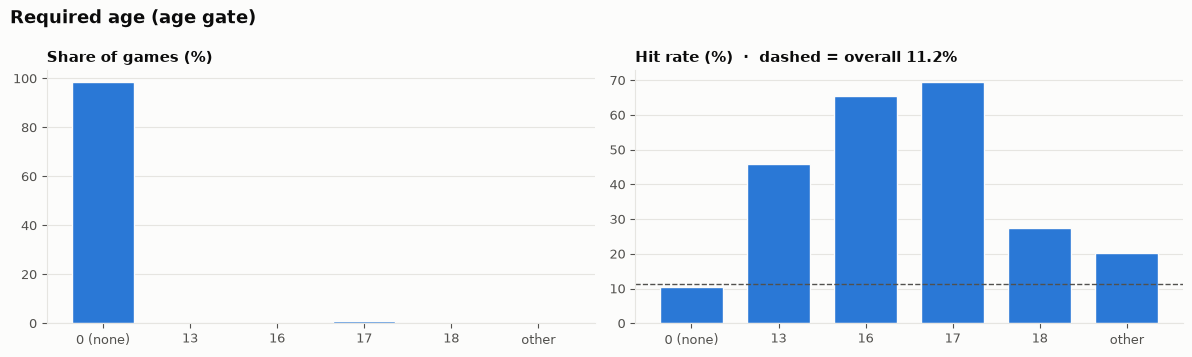

,games,share_%,hits,hit_rate_%
required_age,,,,
0 (none),69619,98.4,7282,10.5
13,153,0.2,70,45.8
16,32,0.0,21,65.6
17,741,1.0,514,69.4
18,139,0.2,38,27.3
other,64,0.1,13,20.3


In [17]:
age = g["required_age"].where(g["required_age"].isin([0, 13, 16, 17, 18]), other=-1)
age_lab = age.map({0: "0 (none)", 13: "13", 16: "16", 17: "17", 18: "18", -1: "other"})
share_and_rate(age_lab, "Required age (age gate)", order=["0 (none)", "13", "16", "17", "18", "other"])

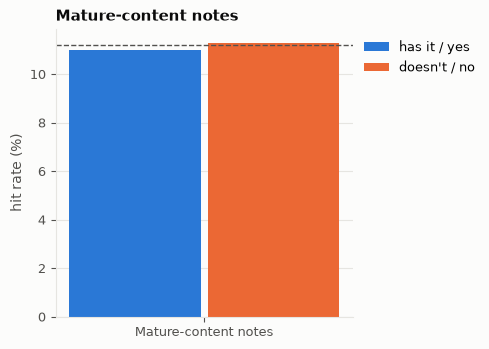

,% of games with it,hit rate % — yes,hit rate % — no
feature,,,
Mature-content notes,17.2,11.0,11.3


In [18]:
flag_chart(["has_mature_notes"], ["Mature-content notes"], "Mature-content notes")

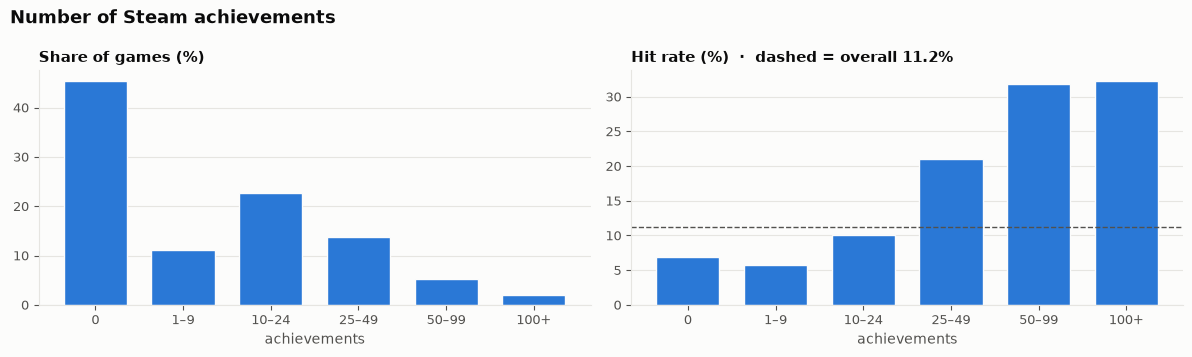

,games,share_%,hits,hit_rate_%
Achievements,,,,
0,32078,45.3,2211,6.9
1–9,7882,11.1,449,5.7
10–24,15987,22.6,1612,10.1
25–49,9676,13.7,2032,21.0
50–99,3722,5.3,1182,31.8
100+,1403,2.0,452,32.2


In [19]:
ach_bin = pd.cut(g["Achievements"], [-1, 0, 9, 24, 49, 99, 100_000],
                 labels=["0", "1–9", "10–24", "25–49", "50–99", "100+"])
share_and_rate(ach_bin, "Number of Steam achievements", "achievements")

**Takeaways — content & audience**
- **Required age:** 98 % of games have no age gate (10.5 % hit rate). The ~1,100 age-gated games hit far more often (age 13: 46 %, age 16: 66 %, age 17: 69 %) — age ratings usually come with bigger, professionally rated releases. Small groups, so treat with care.
- **Mature-content notes make no difference** (11.0 % vs 11.3 %, AUC 0.50) → candidate to drop.
- **Achievements** are the second-strongest feature (AUC 0.67): 0 achievements → 6.9 %, 25–49 → 21 %, 50+ → about 32 %. ⚠️ Gray area: developers can add achievements after launch.

---
# 6. Business setup — `self_published`

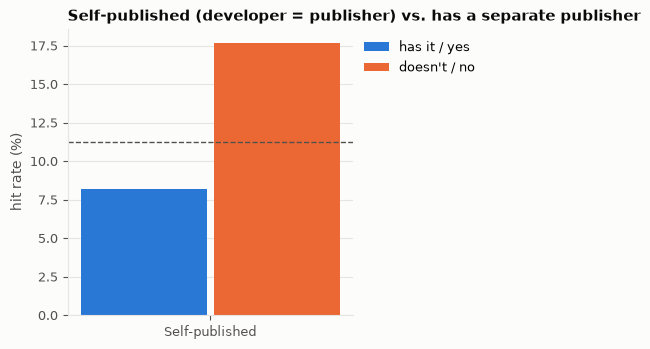

,% of games with it,hit rate % — yes,hit rate % — no
feature,,,
Self-published,68.1,8.2,17.7


In [20]:
flag_chart(["self_published"], ["Self-published"], "Self-published (developer = publisher) vs. has a separate publisher")

Not a model feature yet, but worth seeing: **how many games the developer has in the dataset.** ⚠️ This uses the whole dataset (including later releases), so it's for exploration only; a real feature would have to count only *earlier* games.

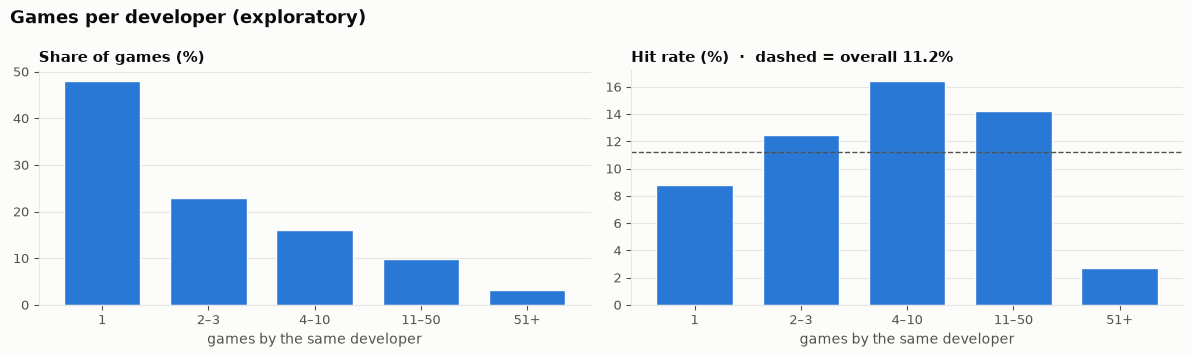

,games,share_%,hits,hit_rate_%
Developers,,,,
1,33895,47.9,2982,8.8
2–3,16285,23.0,2035,12.5
4–10,11356,16.1,1867,16.4
11–50,6989,9.9,994,14.2
51+,2216,3.1,60,2.7


In [21]:
dev_n = g["Developers"].map(g["Developers"].value_counts())
dev_bin = pd.cut(dev_n, [0, 1, 3, 10, 50, 10_000], labels=["1", "2–3", "4–10", "11–50", "51+"])
share_and_rate(dev_bin, "Games per developer (exploratory)", "games by the same developer")

**Takeaways — business setup**
- **Self-published games hit half as often** (8.2 % vs 17.7 % with a separate publisher). 68 % of games are self-published. AUC 0.40 — a strong *negative* signal.
- Developer portfolio size (exploratory): one-game developers 8.8 %, 4–10 games 16.4 %, but studios with **51+ games hit only 2.7 %** — high-volume, low-effort releases. A point-in-time "developer track record" feature looks promising for later.

---
# 7. Release timing — `release_month`, `release_weekday`

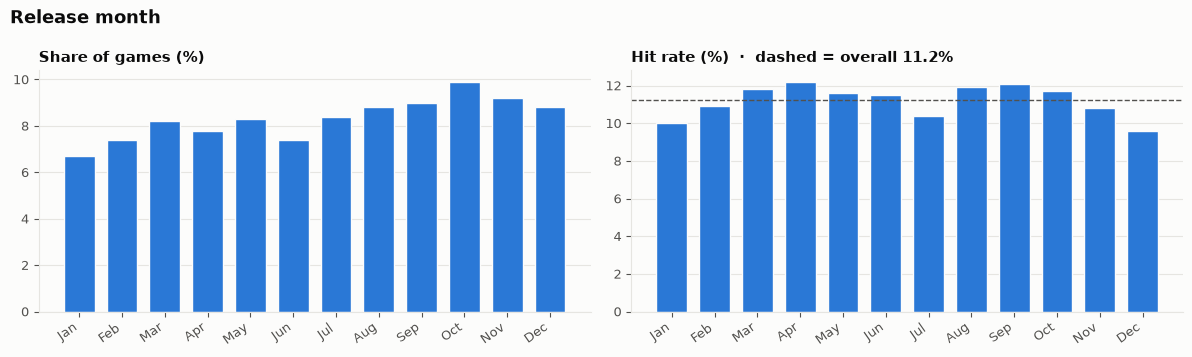

,games,share_%,hits,hit_rate_%
release_month,,,,
Jan,4747,6.7,475,10.0
Feb,5251,7.4,573,10.9
Mar,5769,8.2,679,11.8
Apr,5546,7.8,678,12.2
May,5900,8.3,684,11.6
Jun,5246,7.4,602,11.5
Jul,5947,8.4,616,10.4
Aug,6255,8.8,747,11.9
Sep,6349,9.0,766,12.1


In [22]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
share_and_rate(g["release_month"].map(dict(enumerate(months, 1))), "Release month", order=months)

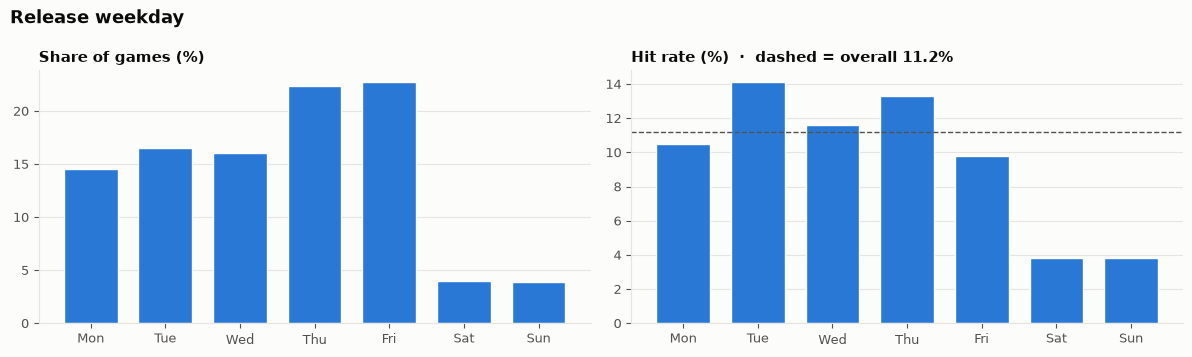

,games,share_%,hits,hit_rate_%
release_weekday,,,,
Mon,10229,14.5,1079,10.5
Tue,11700,16.5,1652,14.1
Wed,11322,16.0,1315,11.6
Thu,15834,22.4,2110,13.3
Fri,16082,22.7,1571,9.8
Sat,2852,4.0,107,3.8
Sun,2729,3.9,104,3.8


In [23]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
share_and_rate(g["release_weekday"].map(dict(enumerate(days))), "Release weekday", order=days)

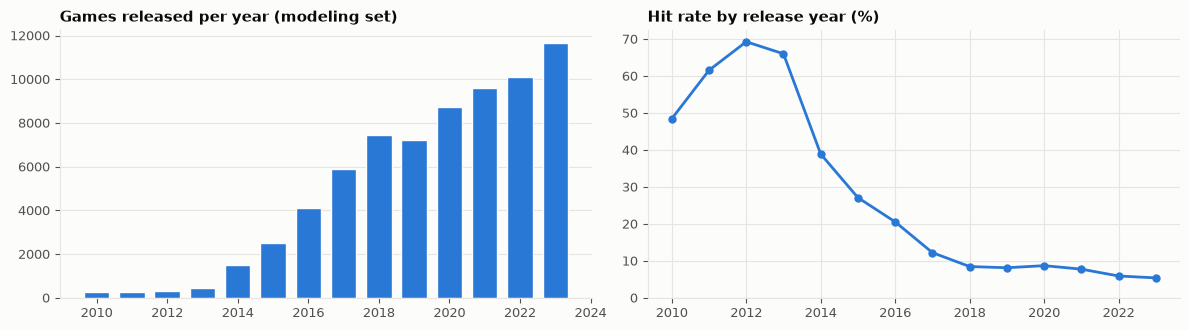

In [24]:
# Context (not a feature): the store gets more crowded every year. Two separate panels, one scale each.
by_year = g[g["release_dt"].dt.year >= 2010].groupby(g["release_dt"].dt.year)["is_hit"].agg(["size", "mean"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4))
a1.bar(by_year.index, by_year["size"], color=BLUE, width=0.72, edgecolor=SURFACE, linewidth=1)
a1.set_title("Games released per year (modeling set)")
a1.grid(axis="x", visible=False)
a2.plot(by_year.index, by_year["mean"] * 100, color=BLUE, marker="o", ms=5)
a2.set_title("Hit rate by release year (%)")
a2.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

**Takeaways — release timing**
- **Release month carries almost no signal** (9.6 % in December to 12.2 % in April; AUC 0.50) → candidate to drop.
- **Weekday matters more:** Tuesday (14.1 %) and Thursday (13.3 %) are best; **weekend releases hit only 3.8 %** (8 % of games). Friday is 9.8 %. Encode weekday as categories or an `is_weekend` flag rather than a 0–6 number.
- Context: hit rate falls with release year as the store gets more crowded — one reason the meeting-prep notebook splits train/test by date.

---
# 8. Game type — genre and Steam-category flags

34 genre flags + 59 category flags = 93 columns


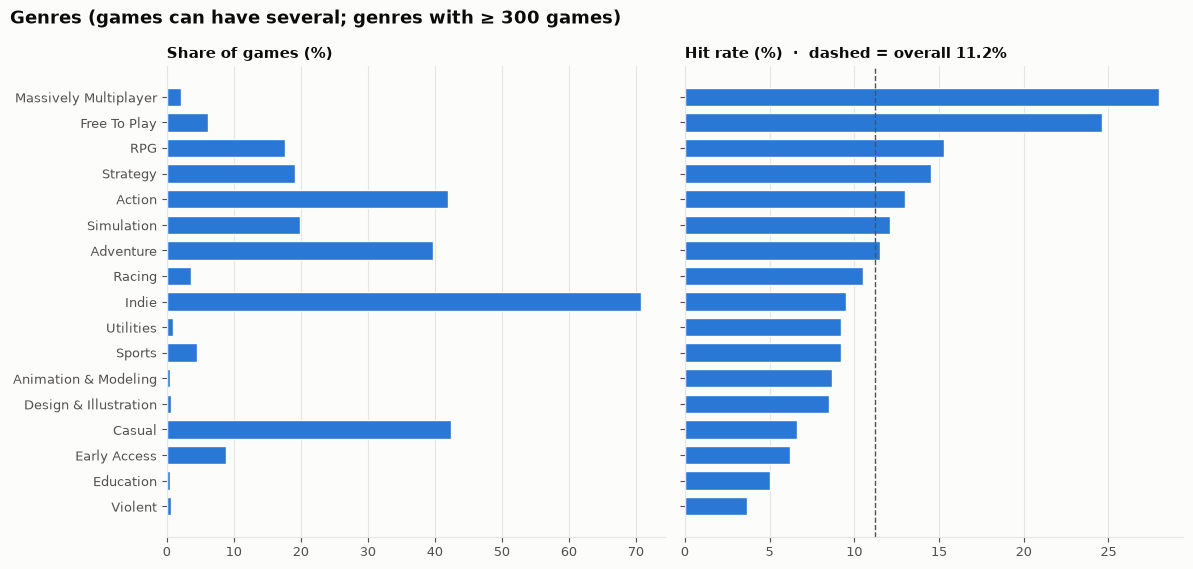

,games,share_%,hits,hit_rate_%
Massively Multiplayer,1484,2.1,415,28.0
Free To Play,4377,6.2,1078,24.6
RPG,12448,17.6,1901,15.3
Strategy,13578,19.2,1975,14.5
Action,29663,41.9,3845,13.0
Simulation,14103,19.9,1710,12.1
Adventure,28066,39.7,3238,11.5
Racing,2565,3.6,269,10.5
Indie,50062,70.8,4734,9.5
Utilities,697,1.0,64,9.2


In [25]:
genres = g["Genres"].fillna("").str.get_dummies(sep=",")
cats = g["Categories"].fillna("").str.get_dummies(sep=",")
print(f"{genres.shape[1]} genre flags + {cats.shape[1]} category flags = {genres.shape[1] + cats.shape[1]} columns")

def flag_table(dummies, min_games=300):
    t = pd.DataFrame({"games": dummies.sum(),
                      "hits": dummies.mul(g["is_hit"], axis=0).sum()})
    t = t[t["games"] >= min_games]
    t["share_%"] = t["games"] / len(g) * 100
    t["hit_rate_%"] = t["hits"] / t["games"] * 100
    return t[["games", "share_%", "hits", "hit_rate_%"]].round(1)

t_genre = flag_table(genres)
share_and_rate_h(t_genre, "Genres (games can have several; genres with ≥ 300 games)")
t_genre.sort_values("hit_rate_%", ascending=False)

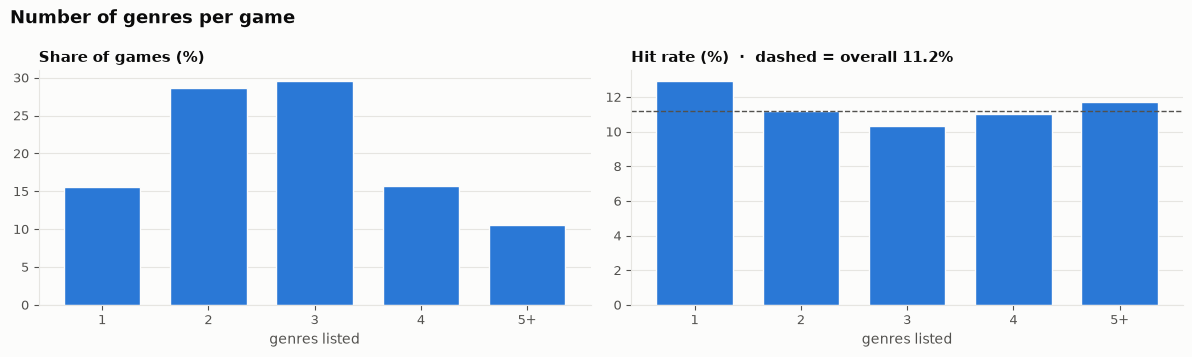

,games,share_%,hits,hit_rate_%
1,11034,15.6,1419,12.9
2,20337,28.7,2280,11.2
3,20846,29.5,2142,10.3
4,11132,15.7,1229,11.0
5+,7399,10.5,868,11.7


In [26]:
n_genres = genres.sum(axis=1)
share_and_rate(pd.cut(n_genres, [-1, 0, 1, 2, 3, 4, 50], labels=["0", "1", "2", "3", "4", "5+"]),
               "Number of genres per game", "genres listed")

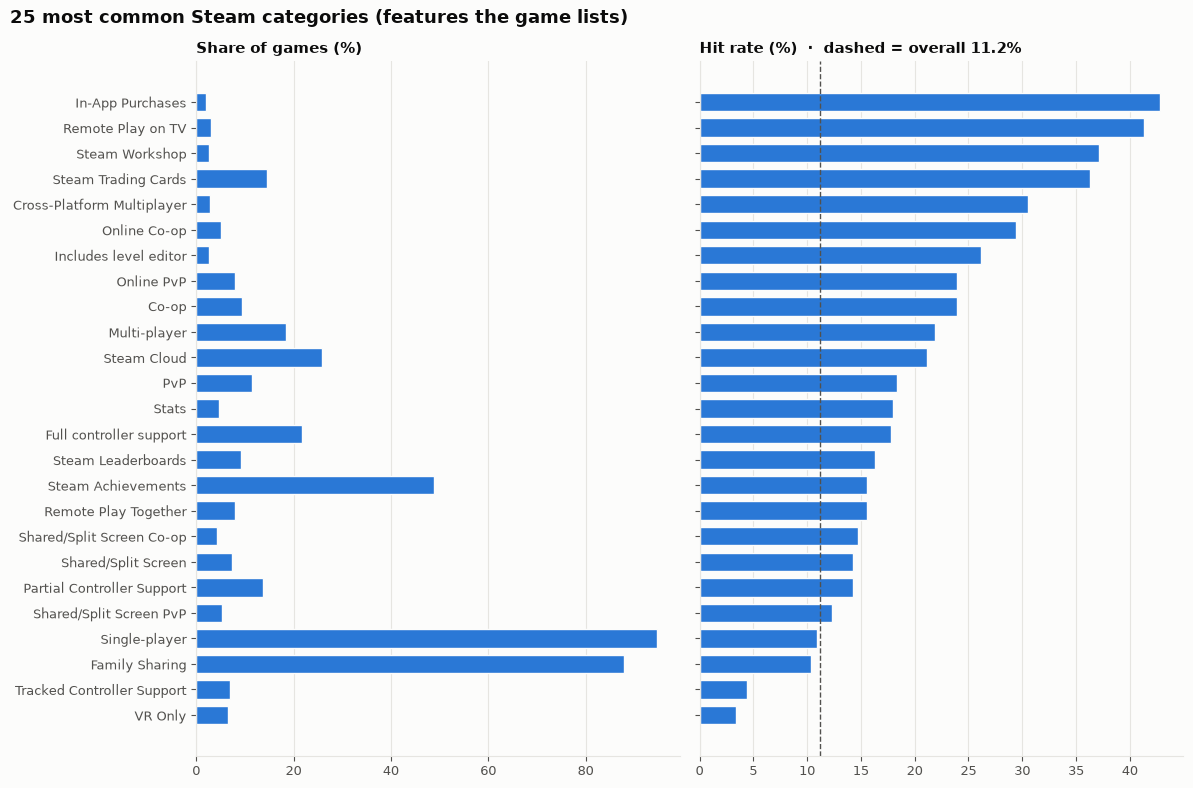

,games,share_%,hits,hit_rate_%
In-App Purchases,1454,2.1,622,42.8
Remote Play on TV,2161,3.1,893,41.3
Steam Workshop,1941,2.7,721,37.1
Steam Trading Cards,10270,14.5,3728,36.3
Cross-Platform Multiplayer,1976,2.8,603,30.5
Online Co-op,3614,5.1,1061,29.4
Includes level editor,1906,2.7,500,26.2
Online PvP,5586,7.9,1335,23.9
Co-op,6692,9.5,1599,23.9
Multi-player,13055,18.5,2861,21.9


In [27]:
t_cat = flag_table(cats, min_games=500)
t_cat = t_cat.sort_values("games", ascending=False).head(25)
share_and_rate_h(t_cat, "25 most common Steam categories (features the game lists)")
t_cat.sort_values("hit_rate_%", ascending=False)

**Takeaways — game type**
- **Genre:** Massively Multiplayer (28.0 %), Free To Play (24.6 %), RPG (15.3 %) and Strategy (14.5 %) are well above average; Casual (6.6 %), Early Access (6.2 %), Education (5.0 %) and Violent (3.7 %) are well below. "Indie" is on 71 % of games and sits below average (9.5 %).
- **Number of genres** listed makes little difference (roughly 10–13 %).
- **Steam categories** with the highest hit rates: In-App Purchases (42.8 %), Remote Play on TV (41.3 %), Steam Workshop (37.1 %), Online Co-op (29.4 %). VR Only (3.4 %) and Tracked Controller Support (4.4 %) are lowest. Single-player (95 %) and Family Sharing (88 %) are on nearly every game and carry little information.
- ⚠️ **`Steam Trading Cards` is probably leakage** (36.3 % hit rate): Valve only enables trading cards for games that meet sales/engagement criteria, so it's granted *after* a game proves itself. Drop that flag, and review other Valve-assigned categories the same way.

---
# 9. Putting it together

### 9.1 Which single feature separates hits from non-hits best?
For each base feature, the **univariate ROC-AUC**: the chance that a randomly chosen hit has a higher value of that feature than a randomly chosen non-hit. 0.5 = no signal. Above 0.5 (blue) → higher values go with more hits; below 0.5 (red) → higher values go with fewer hits.

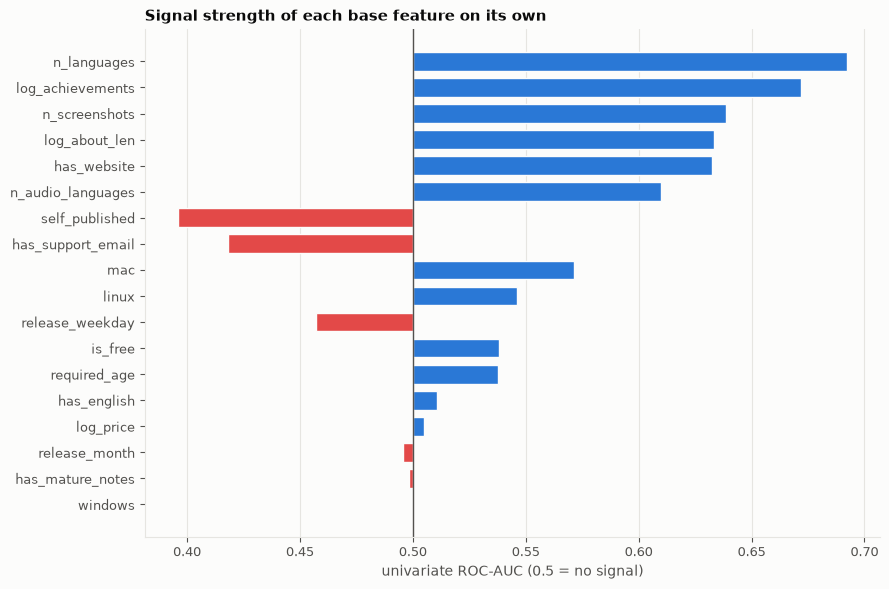

,AUC
n_languages,0.692
log_achievements,0.672
n_screenshots,0.639
log_about_len,0.634
has_website,0.632
n_audio_languages,0.610
mac,0.571
linux,0.546
is_free,0.538
required_age,0.538


In [28]:
def univariate_auc(x, y):
    r = pd.Series(x).rank().to_numpy()
    pos = y.to_numpy() == 1
    n1, n0 = pos.sum(), (~pos).sum()
    return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

aucs = pd.Series({f: univariate_auc(g[f], g["is_hit"]) for f in BASE_FEATURES})
order = (aucs - 0.5).abs().sort_values().index
fig, ax = plt.subplots(figsize=(9, 6))
vals = aucs[order]
ax.barh(order, vals - 0.5, left=0.5, color=[BLUE if v >= 0.5 else RED for v in vals],
        height=0.72, edgecolor=SURFACE, linewidth=1)
ax.axvline(0.5, color=INK2, lw=1)
ax.set_xlabel("univariate ROC-AUC (0.5 = no signal)")
ax.set_title("Signal strength of each base feature on its own")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
aucs.sort_values(ascending=False).round(3).to_frame("AUC")

### 9.2 How the features relate to each other
Rank (Spearman) correlation between the base features. Strongly correlated pairs carry overlapping information — fine for tree models, worth knowing for logistic regression and for interpreting coefficients.

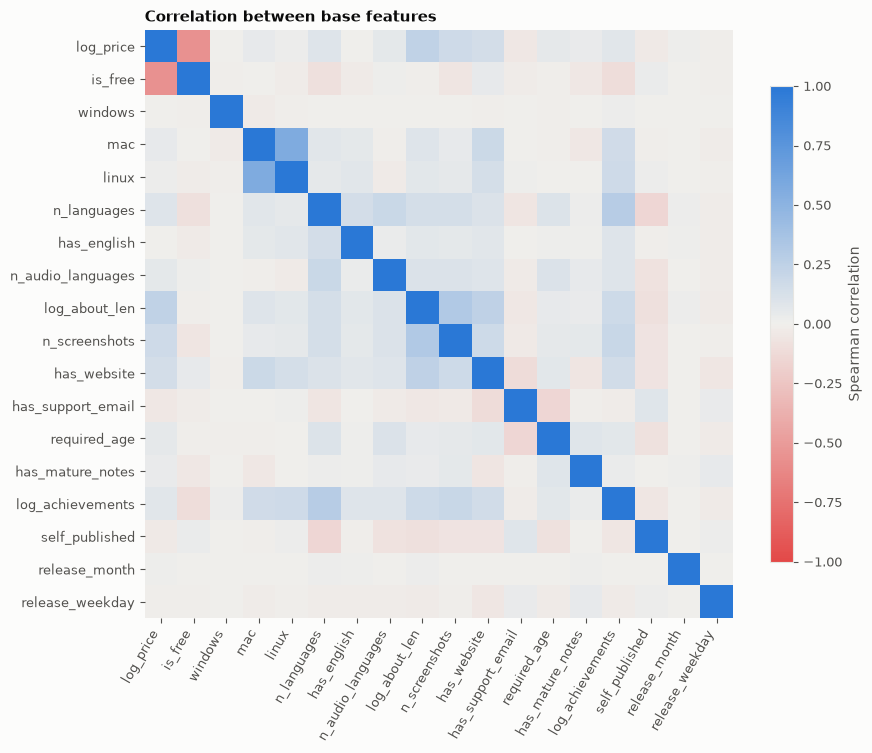

,,correlation
mac,linux,0.56
log_price,is_free,-0.56
log_about_len,n_screenshots,0.32
n_languages,log_achievements,0.29
log_about_len,has_website,0.24
log_price,log_about_len,0.23
n_screenshots,log_achievements,0.20
n_languages,n_audio_languages,0.19


In [29]:
corr = g[BASE_FEATURES].rank().corr()
cmap = LinearSegmentedColormap.from_list("div", [RED, "#f0efec", BLUE])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Spearman correlation")
ax.set_title("Correlation between base features")
fig.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(2).to_frame("correlation")

---
# Summary

**Strongest pre-launch signals (univariate AUC):** number of languages (0.69), achievements (0.67), screenshots (0.64), description length (0.63), website listed (0.63), voiced languages (0.61). Strong *negative* signals: self-published (0.40) and having a support email (0.42). Genre and Steam category flags add more on top (MMO, F2P, RPG, Strategy, Workshop, Co-op…).

**Weak or no signal on their own:** Windows (constant), mature-content notes, release month, has_english, and price — though price matters in a non-linear way (cheap < $2 games do worst).

**Features are not very redundant:** the largest correlations are Mac ↔ Linux and price ↔ free (both about ±0.56); everything else is below 0.35.

**Proposed changes to the feature set:**
1. Drop `windows` (no variation); consider dropping `has_mature_notes` and `release_month`.
2. Encode `release_weekday` as categories or a weekend flag; consider price bands for linear models.
3. Drop the `Steam Trading Cards` category flag (granted after launch → leakage).
4. Ask the instructor about the gray-area features: achievements, screenshot count and description length can all change after launch.
5. Later: add a point-in-time developer track-record feature.

**Bottom line for the meeting:** several features a developer controls before launch — localization, store-page effort, platforms, genre and publisher — clearly separate hits from non-hits, so the prediction task looks learnable without leaky columns.